In [23]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Compare TOC maps from nn-toc and MTL models
"""



'\nCompare TOC maps from nn-toc and MTL models\n'

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LogNorm
import cmcrameri.cm as cmc



In [25]:
# Load TOC map from nn-toc (using code from Visualisation.ipynb)
filename = Path().resolve().parents[2] / "nn-toc" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_supervised_men_CS_noconstraint_v2.npy"
prediction_map_CS = np.load(filename)
prediction_map_DO = np.load(Path().resolve().parents[2] / "nn-toc" / "data" / "output" / "predictionmaps_TOC" / "prediction_map_TOC_noconstraint_DO_v2.npy")

dataset_mask = np.load(Path().resolve().parents[1] / "data" / "interim" / "masks" / "mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_DO
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]

land_file = Path().resolve().parents[2] / "nn-toc-update" / "data" / "raw" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

pm_overlapped[land_map] = np.nan

toc_nntoc = pm_overlapped
print(f"nn-toc TOC map shape: {toc_nntoc.shape}")
print(f"nn-toc TOC map range: [{np.nanmin(toc_nntoc):.3f}, {np.nanmax(toc_nntoc):.3f}]")



nn-toc TOC map shape: (2160, 4320)
nn-toc TOC map range: [0.119, 15.636]


In [26]:
# Load TOC map from MTL model
mtl_toc_path = Path('/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_SedRate/hyperparameter_optimization/prediction_map_toc_entire_MTL_n_test.npy')
toc_mtl = np.load(mtl_toc_path)

# Apply the same transformations as the MTL model uses
#toc_mtl = np.rot90(np.rot90(np.fliplr(toc_mtl)))

# Apply land mask (ensure land_map matches shape)
if land_map.shape != toc_mtl.shape:
    land_map_mtl = land_map[:toc_mtl.shape[0], :toc_mtl.shape[1]]
else:
    land_map_mtl = land_map
toc_mtl[land_map_mtl] = np.nan

print(f"MTL TOC map shape: {toc_mtl.shape}")
print(f"MTL TOC map range: [{np.nanmin(toc_mtl):.3f}, {np.nanmax(toc_mtl):.3f}]")



MTL TOC map shape: (2160, 4320)
MTL TOC map range: [-2.104, 10.136]


In [27]:
# Calculate difference (MTL - nn-toc)
# Ensure both arrays have the same shape
if toc_nntoc.shape != toc_mtl.shape:
    print(f"Warning: Shape mismatch! nn-toc: {toc_nntoc.shape}, MTL: {toc_mtl.shape}")
    # Try to match shapes by cropping to minimum dimensions
    min_rows = min(toc_nntoc.shape[0], toc_mtl.shape[0])
    min_cols = min(toc_nntoc.shape[1], toc_mtl.shape[1])
    toc_nntoc = toc_nntoc[:min_rows, :min_cols]
    toc_mtl = toc_mtl[:min_rows, :min_cols]
    print(f"Adjusted shapes - nn-toc: {toc_nntoc.shape}, MTL: {toc_mtl.shape}")

# Ensure land_map matches the shape
land_map_cropped = land_map[:toc_nntoc.shape[0], :toc_nntoc.shape[1]]

# Calculate difference where both are valid
toc_diff = toc_mtl - toc_nntoc
toc_diff[land_map_cropped] = np.nan

print(f"Difference map range: [{np.nanmin(toc_diff):.3f}, {np.nanmax(toc_diff):.3f}]")
print(f"Mean absolute difference: {np.nanmean(np.abs(toc_diff)):.3f}")



Difference map range: [-7.907, 4.648]
Mean absolute difference: 0.116


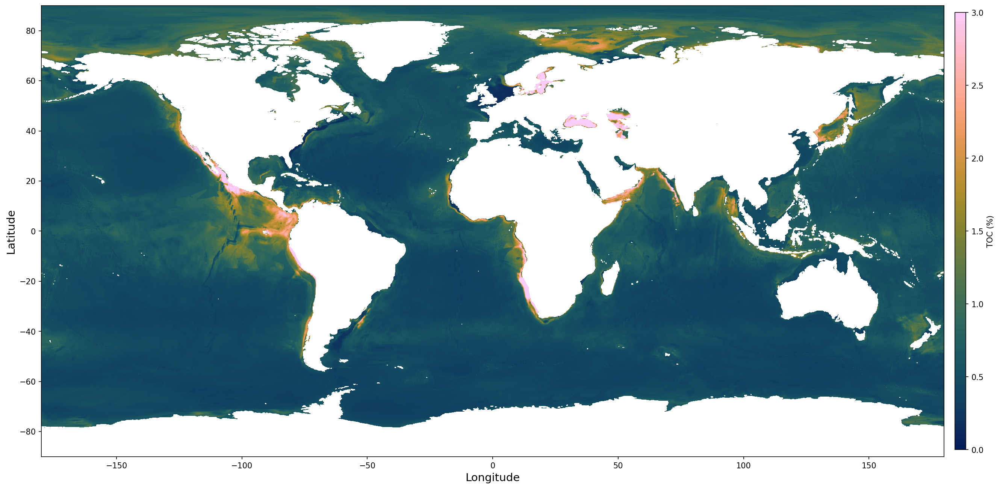

In [28]:
# Plot nn-toc TOC map
plt.figure(figsize=(20, 10), dpi=150)
plt.imshow(toc_nntoc, vmin=0, vmax=3, cmap=cmc.batlow, extent=[-180, 180, -90, 90])
plt.colorbar(label='TOC (%)', aspect=40, pad=0.01, shrink=0.8)
plt.xlabel('Longitude', fontsize=14)
plt.ylabel('Latitude', fontsize=14)
#plt.title('TOC Map from nn-toc Model', fontsize=16)
plt.tight_layout()
"""
# Save figure for manuscript
fig_path = Path().resolve().parents[1] / "docs" / "figures" / "toc_nntoc_map.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
"""
plt.show()



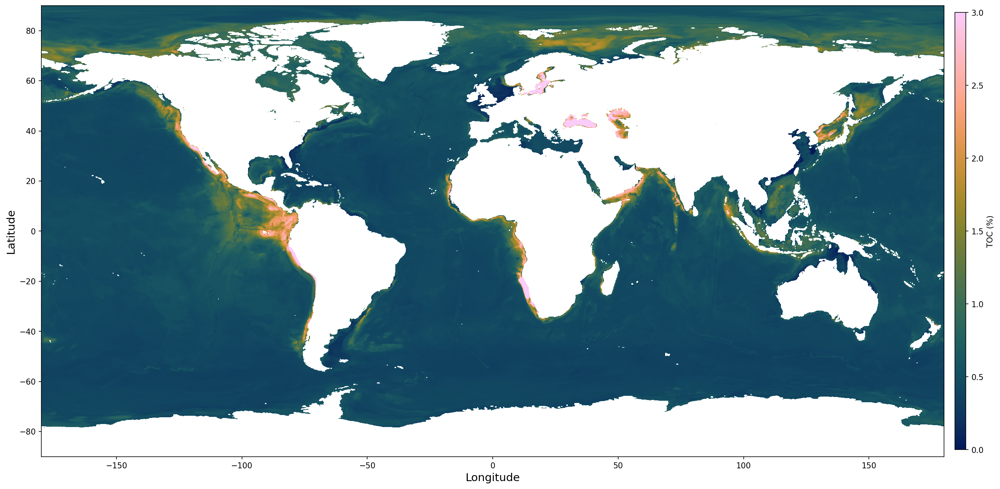

In [29]:
# Plot MTL TOC map
plt.figure(figsize=(20, 10), dpi=150)
plt.imshow(toc_mtl, vmin = 0, vmax = 3, cmap=cmc.batlow, extent=[-180, 180, -90, 90])
plt.colorbar(label='TOC (%)', aspect=40, pad=0.01, shrink=0.8)
plt.xlabel('Longitude', fontsize=14)
plt.ylabel('Latitude', fontsize=14)
#plt.title('TOC Map from MTL Model', fontsize=16)
plt.tight_layout()
"""
# Save figure for manuscript
fig_path = Path().resolve().parents[1] / "docs" / "figures" / "toc_mtl_map.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
"""
plt.show()



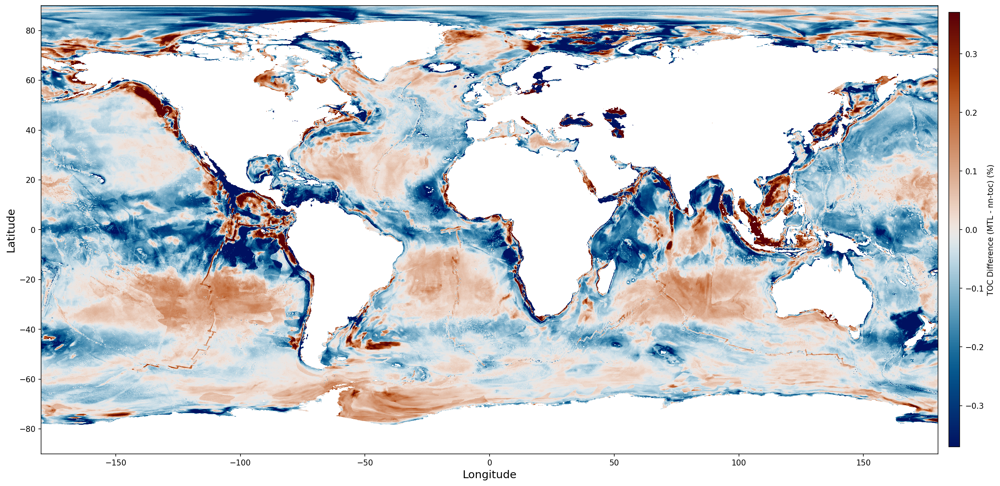

Difference statistics:
  Mean: -0.0508 %
  Std: 0.2079 %
  Median: -0.0314 %
  5th percentile: -0.3193 %
  95th percentile: 0.1554 %


In [ ]:
# Plot difference map (MTL - nn-toc)
# Use a diverging colormap for the difference
vmax_diff = np.nanpercentile(np.abs(toc_diff), 95)  # Use 95th percentile for better visualization
vmin_diff = -vmax_diff

plt.figure(figsize=(20, 10), dpi=150)
im = plt.imshow(toc_diff, cmap=cmc.vik, vmin=vmin_diff, vmax=vmax_diff, extent=[-180, 180, -90, 90])
plt.colorbar(label='TOC Difference (MTL - nn-toc) (%)', aspect=40, pad=0.01, shrink=0.8)
plt.xlabel('Longitude', fontsize=14)
plt.ylabel('Latitude', fontsize=14)
#plt.title('Difference between MTL and nn-toc TOC Predictions', fontsize=16)
plt.tight_layout()
"""
# Save figure for manuscript
fig_path = Path().resolve().parents[1] / "docs" / "figures" / "toc_difference_map.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {fig_path}")
"""
plt.show()

print(f"Difference statistics:")
print(f"  Mean: {np.nanmean(toc_diff):.4f} %")
print(f"  Std: {np.nanstd(toc_diff):.4f} %")
print(f"  Median: {np.nanmedian(toc_diff):.4f} %")
print(f"  5th percentile: {np.nanpercentile(toc_diff, 5):.4f} %")
print(f"  95th percentile: {np.nanpercentile(toc_diff, 95):.4f} %")  



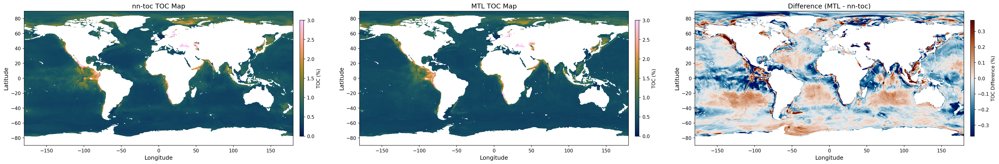

In [34]:
# Create a side-by-side comparison figure
fig, axes = plt.subplots(1, 3, figsize=(30, 10), dpi=150)

# Set colorbar height to be noticeably shorter using a smaller shrink value
colorbar_params = dict(aspect=30, pad=0.02, shrink=0.35)

# nn-toc map
im1 = axes[0].imshow(toc_nntoc, vmin=0, vmax=3, cmap=cmc.batlow, extent=[-180, 180, -90, 90])
axes[0].set_xlabel('Longitude', fontsize=12)
axes[0].set_ylabel('Latitude', fontsize=12)
axes[0].set_title('nn-toc TOC Map', fontsize=14)
plt.colorbar(im1, ax=axes[0], label='TOC (%)', **colorbar_params)

# MTL map
im2 = axes[1].imshow(toc_mtl, vmin=0, vmax=3, cmap=cmc.batlow, extent=[-180, 180, -90, 90])
axes[1].set_xlabel('Longitude', fontsize=12)
axes[1].set_ylabel('Latitude', fontsize=12)
axes[1].set_title('MTL TOC Map', fontsize=14)
plt.colorbar(im2, ax=axes[1], label='TOC (%)', **colorbar_params)

# Difference map
vmax_diff = np.nanpercentile(np.abs(toc_diff), 95)
vmin_diff = -vmax_diff
im3 = axes[2].imshow(toc_diff, cmap=cmc.vik, vmin=vmin_diff, vmax=vmax_diff, extent=[-180, 180, -90, 90])
axes[2].set_xlabel('Longitude', fontsize=12)
axes[2].set_ylabel('Latitude', fontsize=12)
axes[2].set_title('Difference (MTL - nn-toc)', fontsize=14)
plt.colorbar(im3, ax=axes[2], label='TOC Difference (%)', **colorbar_params)

plt.tight_layout()
plt.show()
